Upload 3 grayscale images:


Saving image1.png to image1.png
Saving image2.png to image2.png
Saving image3.png to image3.png


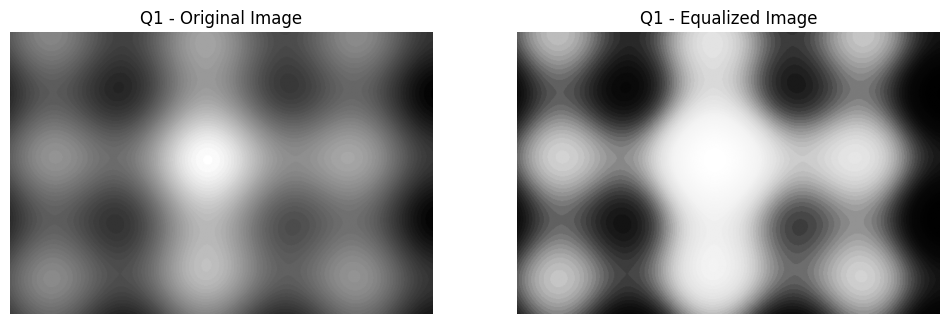

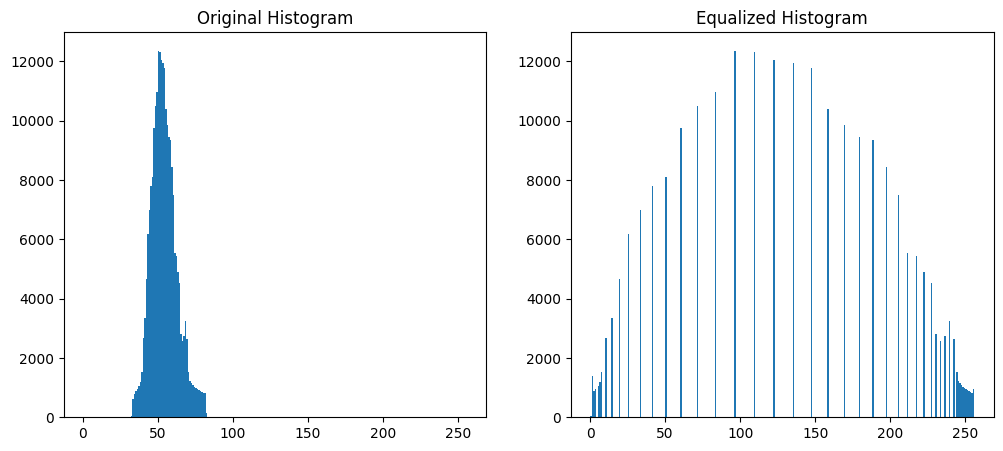

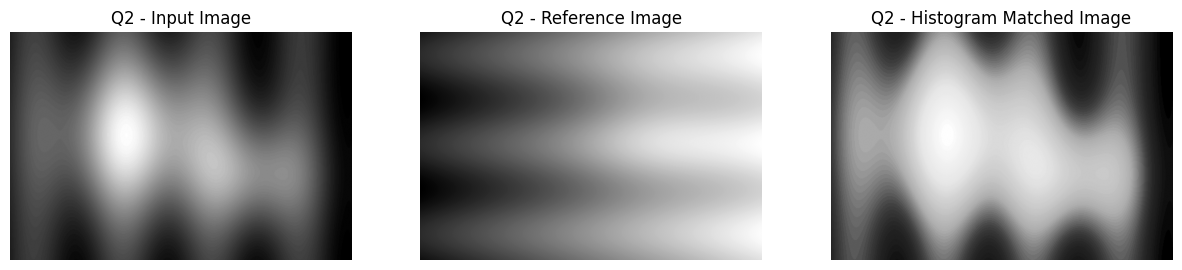

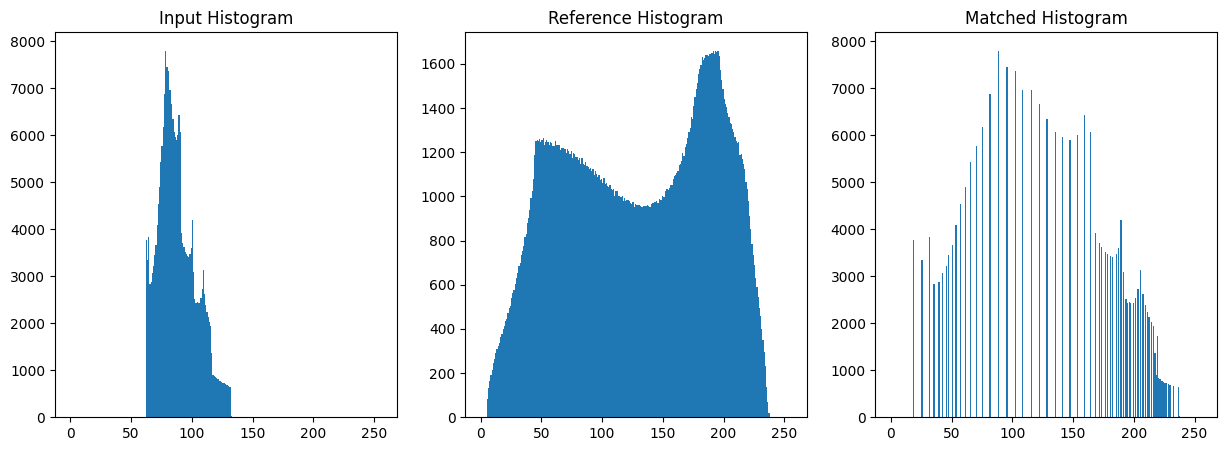

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files



print("Upload 3 grayscale images:")
uploaded = files.upload()

files_list = list(uploaded.keys())


img1 = cv2.imread(files_list[0], cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread(files_list[1], cv2.IMREAD_GRAYSCALE)
reference = cv2.imread(files_list[2], cv2.IMREAD_GRAYSCALE)


#Q1



hist = np.zeros(256, dtype=int)

for pixel in img1.flatten():
    hist[pixel] += 1


pdf = hist / img1.size


cdf = np.cumsum(pdf)


cdf_min = cdf[cdf > 0][0]


equalized_map = np.round(
    ((cdf - cdf_min) / (1 - cdf_min)) * 255
).astype(np.uint8)


equalized_img = equalized_map[img1]



plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap='gray')
plt.title("Q1 - Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_img, cmap='gray')
plt.title("Q1 - Equalized Image")
plt.axis("off")

plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(img1.ravel(), bins=256, range=[0, 256])
plt.title("Original Histogram")

plt.subplot(1, 2, 2)
plt.hist(equalized_img.ravel(), bins=256, range=[0, 256])
plt.title("Equalized Histogram")

plt.show()

#Q2


def get_cdf(img):

    hist = np.zeros(256, dtype=int)

    for pixel in img.flatten():
        hist[pixel] += 1

    pdf = hist / img.size
    cdf = np.cumsum(pdf)

    return hist, cdf



input_hist, input_cdf = get_cdf(img2)
reference_hist, reference_cdf = get_cdf(reference)



mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):


    difference = np.abs(reference_cdf - input_cdf[i])

    mapping[i] = np.argmin(difference)



matched_img = mapping[img2]



plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img2, cmap='gray')
plt.title("Q2 - Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference, cmap='gray')
plt.title("Q2 - Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title("Q2 - Histogram Matched Image")
plt.axis("off")

plt.show()



plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(img2.ravel(), bins=256, range=[0, 256])
plt.title("Input Histogram")

plt.subplot(1, 3, 2)
plt.hist(reference.ravel(), bins=256, range=[0, 256])
plt.title("Reference Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_img.ravel(), bins=256, range=[0, 256])
plt.title("Matched Histogram")

plt.show()